<div style='background-color:#EEF4F7; border-left:4px solid #6F8996; border-radius:6px; padding:14px 18px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Project Code - Stroke Prediction</h1>
<p style="color:#243038; margin:0.4em 0;"><strong>LTAT.02.002 Introduction to Data Science - Autumn 2026</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Authors: Voldemar Kirss, Tormi Arne Raidvere</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Team code: H7</strong></p>

</div>

This notebook is about stroke prediction. The data is from Kaggle. In this file there will be some descriptive analysis about the data and also use of different machine learning algorithms to predict stroke.

In [42]:
#Necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

In [2]:
data = pd.read_csv("healthcare-dataset-stroke-data.csv")
print(data.shape)
data.head()

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


We can see that the data has 5110 rows and 12 columns, one of them being unique id for each person. We have 11 indicators, most of them about health and others about different living conditions.

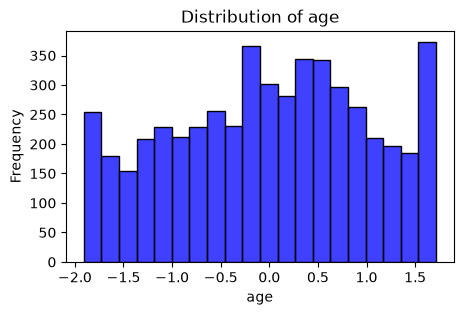

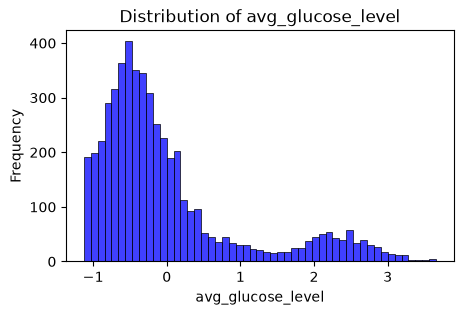

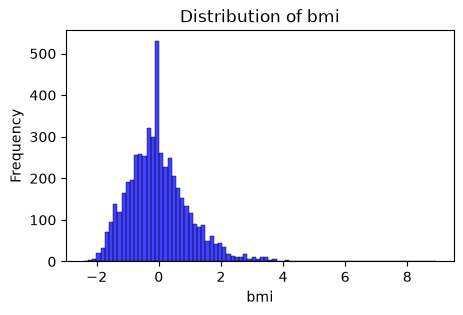

In [45]:
for el in ["age", "avg_glucose_level", "bmi"]:
    plt.figure(figsize=(5,3))
    sns.histplot(data[el], color="blue")
    plt.ylabel('Frequency')
    plt.xlabel(el)
    plt.title(f'Distribution of {el}')
    plt.show()

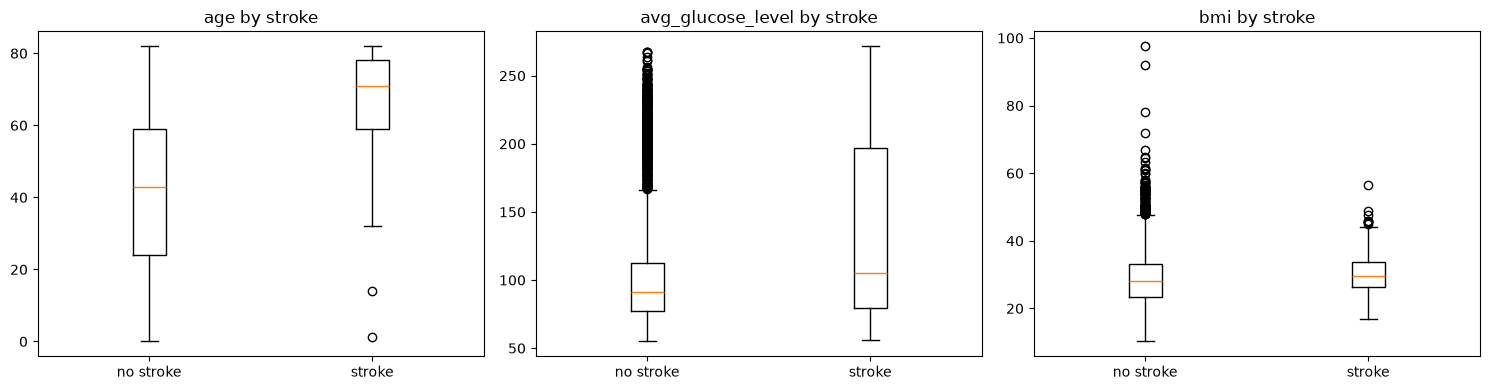

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    data_1 = [data[data["stroke"] == s][col].dropna() for s in [0, 1]]
    ax.boxplot(data_1, tick_labels=["no stroke", "stroke"])
    ax.set_title(col + " by stroke")
plt.tight_layout()
plt.show()

In [6]:
# DATA CLEANUP

copy = data.copy()

# id column gives us no useful information
data = data.drop(columns="id")

# bmi column has missing values, let's fill them with mean
data.bmi = data.bmi.fillna(data.bmi.mean())

# One hot encoding
data_dum = pd.get_dummies(data,columns=["gender", "ever_married", "work_type", "Residence_type", "smoking_status"],dtype=int)

# Numerical value standarization (so that one column wouldn't dominate)
for el in ['age', 'avg_glucose_level', 'bmi']:
    n = len(data_dum[el])
    mean = sum(data_dum[el])/n
    variance = sum((x-mean)**2 for x in data_dum[el])/n
    standard_deviation = np.sqrt(variance)
    data_dum[el] = [(x-mean)/standard_deviation for x in data_dum[el]]

data = data_dum.copy()

In [34]:
# method eeldab, et predict_proba töötab/on olemas
#allpool on näited ka
def predict_and_graph(df, method, randomstate):
    #Split the data
    X = df.drop(columns=['stroke'])
    y = df['stroke']
    X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=randomstate,stratify=y)
    # We use stratify=y because the data is imbalanced. This way the split takes that into account.

    #Predicting
    rf = method.fit(X_train,y_train)
    y_pred_rf = rf.predict(X_test)
    y_proba_rf = rf.predict_proba(X_test)[:, 1]

    
    print("Classification Report")
    print(classification_report(y_test, y_pred_rf, zero_division=0))

    #Confusion matrix graph
    matrix = confusion_matrix(y_test, y_pred_rf)
    sns.heatmap(matrix, annot=True, fmt = "d", cmap = "Blues")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix")
    plt.show()
    
    # ROC & AUC
    fpr, tpr, th = roc_curve(y_test, y_proba_rf)
    auc_rf = roc_auc_score(y_test, y_proba_rf)
    print("AUC ROC:", auc_rf)
    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr, label=f"AUC = {auc_rf:.3f}")
    plt.plot([0,1],[0,1],"-",color="grey")
    plt.title("ROC")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    
    plt.legend()
    plt.show()

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>x

<h1 style="color:#243038; margin:0.2em 0;">X</h1>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Y</h1>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Data visualization</h1>

</div>

Classification Report (Random Forest)
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



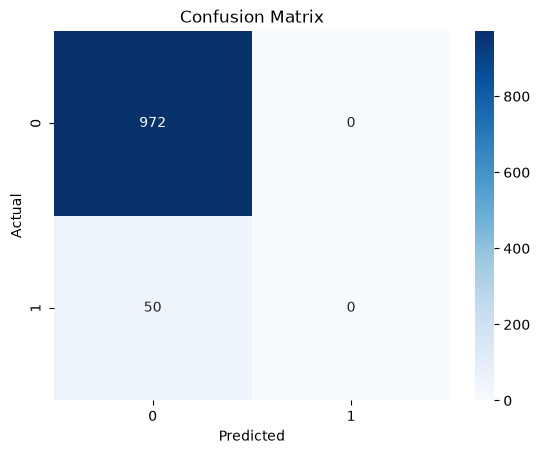

AUC ROC: 0.8117283950617283


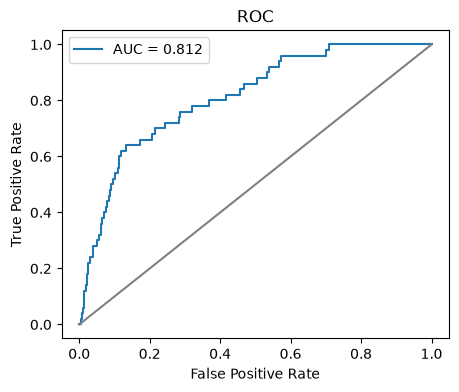

In [35]:
predict_and_graph(data,RandomForestClassifier(n_estimators=100,max_depth=4,random_state=1),1)

Classification Report (Random Forest)
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       972
           1       0.11      0.12      0.11        50

    accuracy                           0.91      1022
   macro avg       0.53      0.53      0.53      1022
weighted avg       0.91      0.91      0.91      1022



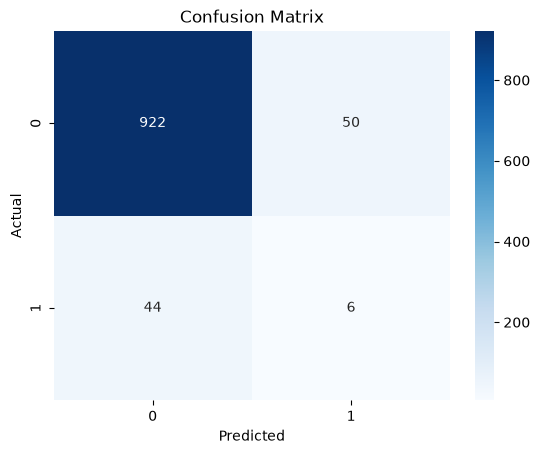

AUC ROC: 0.5342798353909466


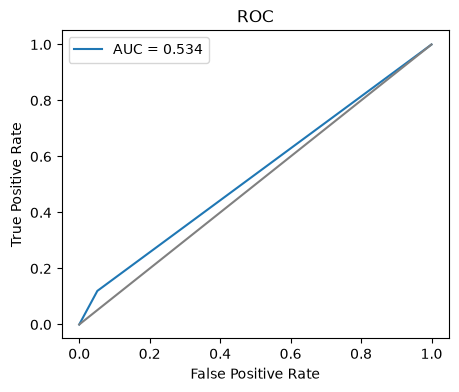

In [40]:
predict_and_graph(data,DecisionTreeClassifier(criterion='entropy',random_state=0),1)

In [44]:
#see allolev ei tööta, sest selle suure funktsiooniga, sest predict_proba pole selle jaoks
#peab eraldi tegema, ei saa suurt funktsiooni kasutada
#predict_and_graph(data,SVC(kernel="rbf",gamma="auto"),1)